# 01 · Datenverständnis und Datenqualität

**Projekt:** Angebotene Übernachtungspreise von Airbnb-Inseraten in Paris (Snapshot 16.09.2026)
**Modul:** Statistik für Data Science, HSG, HS2026

**Hauptfrage des Projekts.** Wie unterscheiden sich die auf Airbnb angebotenen Preise pro Nacht für Inserate in Paris nach Unterkunftsart, Kapazität und Arrondissement, und wie robust sind diese Unterschiede gegenüber extremen Preisen, den Bedingungen der Preisabfrage und Mehrfachinseraten derselben Hosts?

## Teilfrage 1 (dieses Notebook)

> **Was misst die Preisvariable, für welche Inserate liegt ein Preis vor, und wie unterscheiden sich Inserate mit Preis von solchen ohne Preis?**

**Warum zuerst diese Frage?** Jede spätere Kennzahl hängt davon ab, was in sie eingeht. VL01 und NB01 verlangen deshalb eine feste Reihenfolge: zuerst Struktur und Messniveaus, dann der Entstehungsprozess der Daten, dann die Muster der fehlenden Werte und erst danach Kennzahlen und Bilder (NB01 §5, Schritte 1–6). Am Ende dieses Notebooks steht der **Analysedatensatz**, mit dem die Notebooks 02 bis 04 arbeiten, zusammen mit einer Bereinigungstabelle.

**Vorlesungsbezug:** VL01 S. 8–13 (Messniveaus), S. 19–26 (Bias), S. 31–36 (MCAR, MAR, MNAR und Strategiematrix), S. 40–45 (EDA). TA-Vorlage: NB01 §1–§5.

**Aufbau**

1. Quelle, Snapshot und Beobachtungseinheit
2. IDs, Duplikate und Messniveaus
3. Was misst `price`?
4. Fehlende Werte und ihre Muster
5. Selektionsfolgen: Inserate mit und ohne Preis im Vergleich
6. Ungültige und unplausible Werte
7. Bereinigungstabelle und Analysedatensatz
8. Abhängigkeit durch Mehrfach-Hosts
9. Antwort auf Teilfrage 1

## 0. Setup
Die Pakete, Versionen und den Seed halten wir fest, wie es der Syllabus verlangt (NB01, Zelle 2). Alle Pfade sind relativ zur Projektwurzel.

In [1]:
import sys
from pathlib import Path

# Projektwurzel finden (Ordner mit src/), damit relative Pfade unabhängig vom Startordner gelten
PROJEKT = Path.cwd().resolve()
while not (PROJEKT / "src").is_dir():
    PROJEKT = PROJEKT.parent
sys.path.insert(0, str(PROJEKT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from scipy import stats

from src import daten as D
from src import grafik as G

G.stil()
SEED = D.SEED
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "'"))

print("Python    ", sys.version.split()[0])
for modul in (np, pd, scipy, matplotlib, sns):
    print(f"{modul.__name__:10s}", modul.__version__)
print("Seed      ", SEED)
print("Snapshot  ", D.SNAPSHOT)

Python     3.14.2
numpy      2.5.4
pandas     3.1.1
scipy      1.18.1
matplotlib 3.11.2
seaborn    0.13.2
Seed       42
Snapshot   2026-09-16


---
## 1. Quelle, Snapshot und Beobachtungseinheit

| Merkmal | Wert |
|---|---|
| Quelle | Inside Airbnb, <https://insideairbnb.com/get-the-data/>, Abschnitt «Paris, Île-de-France» |
| Datei | `listings.csv.gz` (detaillierte Inseratsliste), Snapshot **2026-09-16** |
| Dokumentation | Data Dictionary «listings.csv detailed file», Version 4.3 (August 2022), Kopie in `data/raw/paris_2026-09-16/data_dictionary_listings_v4.3.csv` |
| Heruntergeladen | 10.11.2026; die Prüfsumme (SHA-256) sichert, dass alle mit derselben Datei rechnen |

Die Funktion `D.stelle_rohdatei_bereit()` lädt die Datei herunter, falls sie fehlt, und bricht ab, wenn die Prüfsumme nicht stimmt. Die Rohdatei wird **nie verändert**. Alle abgeleiteten Grössen entstehen als neue Spalten in `src/daten.py`.

In [2]:
pfad = D.stelle_rohdatei_bereit()
print("Rohdatei:", pfad.relative_to(PROJEKT))
print("SHA-256 :", D.sha256(pfad), "(entspricht der dokumentierten Prüfsumme)")

roh = D.lade_rohdaten()
print(f"\nForm: {roh.shape[0]:,} Zeilen × {roh.shape[1]} Spalten".replace(",", "'"))
print("scrape_id:", roh["scrape_id"].unique())
print("last_scraped:", roh["last_scraped"].min(), "bis", roh["last_scraped"].max())

Rohdatei: data/raw/paris_2026-09-16/listings.csv.gz
SHA-256 : 3285e5096c1869a684d5e65eb38526f07aa16bdc41cd76686feba8a2b78bd019 (entspricht der dokumentierten Prüfsumme)



Form: 77'149 Zeilen × 90 Spalten
scrape_id: [20260916052215]
last_scraped: 2026-09-17 bis 2026-09-24


**Was eine Zeile ist.** Jede Zeile ist **ein Inserat** (`id`), so wie Inside Airbnb es beim Scrape gesehen hat. Alle Inserate stammen aus einem einzigen Scrape (`scrape_id`). Die Seiten wurden zwischen dem 17. und dem 24.09.2026 abgerufen. Eine Zeile ist **keine** Buchung, kein Gast und keine physische Wohnung: Ein Host kann dieselbe Wohnung mehrfach inserieren.

Alle Aussagen der Notebooks beziehen sich deshalb auf **Inserate zu diesem Zeitpunkt**. Wenn wir einen Median berichten, ist das der Median über Inserate, nicht über Übernachtungen.

**Wer überhaupt im Datensatz ist (VL01 S. 20, Sampling Bias).** Inside Airbnb findet Inserate über eine Suche nach Stadtquartieren. Laut Data Dictionary enthält `source` zusätzlich Inserate aus früheren Scrapes der letzten 65 Tage, die noch online waren. Was die Suche nicht liefert, fehlt. Diese Lücke können wir nicht beziffern, wir nennen sie deshalb als Grenze.

---
## 2. IDs, Duplikate und Messniveaus

In [3]:
print("id eindeutig:           ", roh["id"].is_unique)
print("doppelte Zeilen:        ", int(roh.duplicated().sum()))
print("Anzahl Hosts (host_id): ", f"{roh['host_id'].nunique():,}".replace(",", "'"))
print("Arrondissements:        ", roh["neighbourhood_cleansed"].nunique())
print("neighbourhood_group leer:", roh["neighbourhood_group_cleansed"].isna().all())

id eindeutig:            True


doppelte Zeilen:         0
Anzahl Hosts (host_id):  54'481
Arrondissements:         20
neighbourhood_group leer: True


Die IDs sind eindeutig, es gibt keine doppelten Zeilen. `neighbourhood_cleansed` enthält die 20 Pariser Arrondissements (mit Namen statt Nummern), `neighbourhood_group_cleansed` ist in Paris vollständig leer und wird nicht verwendet.

**Messniveaus.** Der dtype sagt nichts über das Messniveau (NB01 §1). Die folgende Zuordnung ist eine inhaltliche Entscheidung, deshalb steht sie von Hand im Code.

In [4]:
# Hand-Mapping: Messniveau und Rolle der Variablen, die wir verwenden
MESSNIVEAU = {
    "price":                  ("ratio (nach Parsing)", "Zielvariable: Abfragepreis pro Nacht"),
    "room_type":              ("nominal", "Gruppierung"),
    "accommodates":           ("ratio, diskret", "Kapazität (max. Gäste)"),
    "bedrooms":               ("ratio, diskret", "Kapazität, Gegenprobe"),
    "neighbourhood_cleansed": ("nominal", "Lage (Arrondissement)"),
    "host_id":                ("nominal", "Abhängigkeit, Host-Cluster"),
    "calculated_host_listings_count": ("ratio, diskret", "Inserate je Host"),
    "minimum_nights":         ("ratio, diskret", "Erklärung der Abfragedauer"),
    "price_quote_checkin_date": ("intervall (Datum)", "Abfragebedingung"),
    "availability_365":       ("ratio, diskret", "nur Erklärung fehlender Preise"),
    "source":                 ("nominal", "nur Erklärung fehlender Preise"),
    "number_of_reviews_ltm":  ("ratio, diskret (Zählung)", "Aktivitätsindikator"),
    "property_type":          ("nominal", "Fallprüfung"),
}

steckbrief = pd.DataFrame(
    {
        "dtype": [str(roh[s].dtype) for s in MESSNIVEAU],
        "eindeutige Werte": [roh[s].nunique() for s in MESSNIVEAU],
        "fehlend": [int(roh[s].isna().sum()) for s in MESSNIVEAU],
        "Messniveau": [v[0] for v in MESSNIVEAU.values()],
        "Rolle": [v[1] for v in MESSNIVEAU.values()],
    },
    index=list(MESSNIVEAU),
)
D.speichere_tabelle(steckbrief, "01_variablen_steckbrief")
steckbrief

,dtype,eindeutige Werte,fehlend,Messniveau,Rolle
price,str,13625,33612,ratio (nach Parsing),Zielvariable: Abfragepreis pro Nacht
room_type,str,4,0,nominal,Gruppierung
accommodates,int64,16,0,"ratio, diskret",Kapazität (max. Gäste)
bedrooms,float64,16,25,"ratio, diskret","Kapazität, Gegenprobe"
neighbourhood_cleansed,str,20,0,nominal,Lage (Arrondissement)
host_id,int64,54481,0,nominal,"Abhängigkeit, Host-Cluster"
calculated_host_listings_count,int64,101,0,"ratio, diskret",Inserate je Host
minimum_nights,float64,115,118,"ratio, diskret",Erklärung der Abfragedauer
price_quote_checkin_date,str,367,29078,intervall (Datum),Abfragebedingung
availability_365,int64,366,0,"ratio, diskret",nur Erklärung fehlender Preise


**Folgen für die Methodenwahl.**

- `price` steht als Text (`str`) in der Datei und muss zuerst geparst werden.
- `room_type` und das Arrondissement sind **nominal**. Für sie berechnen wir keine Korrelation, sondern vergleichen Gruppen (NB04 §6, Schritt 5).
- `accommodates` ist metrisch, hat aber nur 16 Werte und damit sehr viele Ties. Das spricht in NB03 für Rangmasse und für Boxplots je Stufe statt eines Streudiagramms.

---
## 3. Was misst `price`?

Das Data Dictionary sagt: *«daily price in local currency. NOTE: the $ sign is a technical artifact of the export, please ignore it.»*

Der Snapshot von 2026 enthält jedoch Spalten, die **im Data Dictionary v4.3 nicht vorkommen**. Wir prüfen sie, bevor wir dem Preis eine Bedeutung geben.

In [5]:
dokumentiert = set(pd.read_csv(D.ROH_ORDNER / "data_dictionary_listings_v4.3.csv", skiprows=7)["Field"].dropna())
undokumentiert = [s for s in roh.columns if s not in dokumentiert]
print("Spalten im Datensatz, die im Data Dictionary fehlen:")
for s in undokumentiert:
    print("  -", s)

Spalten im Datensatz, die im Data Dictionary fehlen:
  - host_profile_id
  - host_profile_url
  - hosts_time_as_user_years
  - hosts_time_as_user_months
  - hosts_time_as_host_years
  - hosts_time_as_host_months
  - price_quote_checkin_date
  - price_quote_checkout_date
  - price_quote_total_price
  - price_quote_price_per_night
  - price_quote_raw
  - availability_eoy
  - number_of_reviews_ly
  - estimated_occupancy_l365d
  - estimated_revenue_l365d


Unter den nicht dokumentierten Spalten sind die `price_quote_*`-Felder. Ihr Name deutet auf eine **Preisabfrage** hin, also einen simulierten Buchungsversuch für einen bestimmten Termin. Wir prüfen den Zusammenhang mit `price` direkt.

In [6]:
# Aufbereitung aus src/daten.py: parst price, liest das JSON price_quote_raw, leitet Abfragedauer ab
alle, kern, bereinigung = D.bereite_auf(roh)

mit_preis = alle[alle["preis_eur"].notna()]
beide = mit_preis["price_quote_price_per_night"].notna()

# Prüfung 1: Ist price identisch mit dem Preis pro Nacht aus der Abfrage?
gleich = np.isclose(mit_preis.loc[beide, "preis_eur"], mit_preis.loc[beide, "price_quote_price_per_night"])
print(f"price == price_quote_price_per_night: {gleich.mean():.1%} von {beide.sum():,} Inseraten mit beiden Werten".replace(",", "'"))

# Prüfung 2: Ist der Preis pro Nacht = Gesamtpreis der Abfrage / Anzahl Nächte?
ok = beide & mit_preis["price_quote_total_price"].notna() & mit_preis["abfrage_naechte"].gt(0)
quotient = mit_preis.loc[ok, "price_quote_total_price"] / mit_preis.loc[ok, "abfrage_naechte"]
print(f"price == total_price / Nächte:        {np.isclose(quotient, mit_preis.loc[ok, 'preis_eur'], atol=0.02).mean():.1%}")

# Prüfung 3: Währung laut JSON
print("\nWährung in der Abfrage (Inserate mit Preis):")
print(mit_preis["abfrage_waehrung"].value_counts(dropna=False).rename(index={np.nan: "fehlt"}))

# Prüfung 4: Parsing verlustfrei?
print("\nPreis vorhanden, aber nicht parsebar:", int((alle["price"].notna() & alle["preis_eur"].isna()).sum()))

price == price_quote_price_per_night: 100.0% von 43'006 Inseraten mit beiden Werten
price == total_price / Nächte:        100.0%

Währung in der Abfrage (Inserate mit Preis):
abfrage_waehrung
EUR      43006
fehlt      531
Name: count, dtype: int64

Preis vorhanden, aber nicht parsebar: 0


**Beobachtung**

- `price` ist in **allen** Fällen mit beiden Werten identisch mit `price_quote_price_per_night`. Dieser Wert ist (auf 2 Cent genau) immer «Gesamtpreis der Abfrage geteilt durch Anzahl Nächte».
- Die Währung ist überall **EUR**, wo das JSON eine Währung nennt.
- Bei 531 Inseraten mit Preis fehlt die Währung. Das sind genau die Fälle, deren Abfrage «nicht verfügbar» meldet. Wir kennzeichnen sie in Abschnitt 6.
- Alle Preistexte lassen sich verlustfrei in Zahlen umwandeln.

**Interpretation.** `price` ist der **angebotene Preis pro Nacht aus einer Preisabfrage für einen bestimmten Aufenthalt**. Damit hängt er von zwei Bedingungen ab: vom **Termin** und von der **Dauer** der Abfrage. Beides sehen wir uns an.

In [7]:
abfrage = mit_preis[["abfrage_naechte", "abfrage_monatspreis", "abfrage_vorlauf_tage", "minimum_nights"]]

dauer_klassen = pd.cut(abfrage["abfrage_naechte"], [0, 1, 2, 6, 27, 1000], labels=["1", "2", "3–6", "7–27", "≥28"])
tabelle_dauer = pd.crosstab(dauer_klassen, abfrage["abfrage_monatspreis"].fillna(False), margins=True, margins_name="Summe")
tabelle_dauer.columns = ["kein Monatspreis", "Monatspreis", "Summe"]
print("Abfragedauer in Nächten × Monatspreis-Kennzeichen (Inserate mit Preis):")
display(tabelle_dauer)

print(f"Abfragedauer = minimum_nights: {(abfrage['abfrage_naechte'] == abfrage['minimum_nights']).mean():.1%}")
print("Check-in der Abfrage:", alle.loc[mit_preis.index, "abfrage_checkin"].min().date(),
      "bis", alle.loc[mit_preis.index, "abfrage_checkin"].max().date())
print("Vorlauf (Check-in minus Scrape) in Tagen:")
print(abfrage["abfrage_vorlauf_tage"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1).to_string())

Abfragedauer in Nächten × Monatspreis-Kennzeichen (Inserate mit Preis):


,kein Monatspreis,Monatspreis,Summe
abfrage_naechte,,,
1,12129,0,12129
2,11068,0,11068
3–6,12781,0,12781
7–27,1606,0,1606
≥28,3,5950,5953
Summe,37587,5950,43537


Abfragedauer = minimum_nights: 84.8%
Check-in der Abfrage: 2026-09-17 bis 2027-09-20
Vorlauf (Check-in minus Scrape) in Tagen:
count   43'537.00
mean        45.10
std         64.30
min         -5.00
25%          4.00
50%         19.00
75%         55.00
90%        112.00
max        364.00


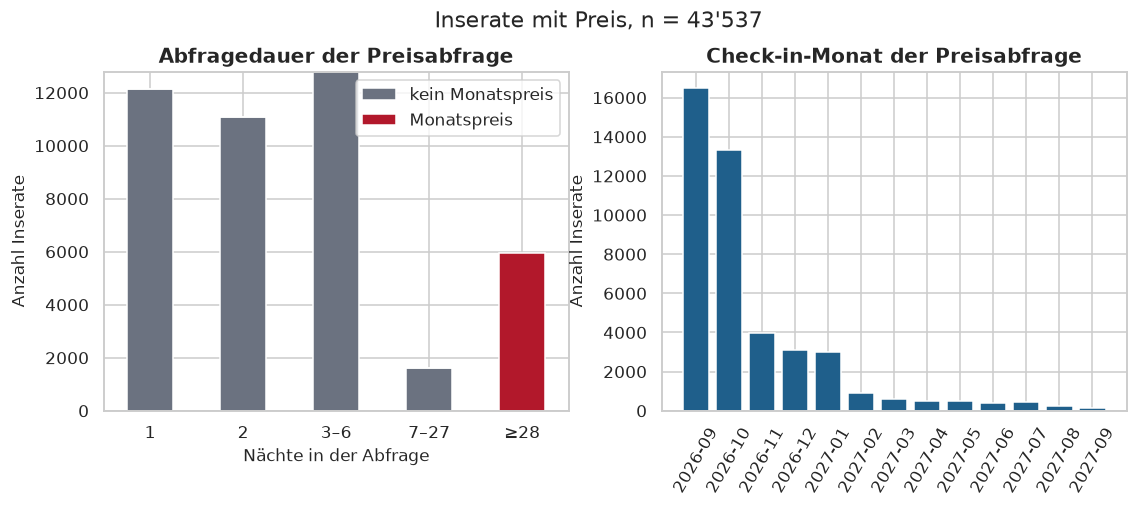

In [8]:
# Darstellen: Abfragedauer und Check-in-Monat der bepreisten Inserate
fig, achsen = plt.subplots(1, 2, figsize=(12, 4))

zaehlung = tabelle_dauer.drop(index="Summe")[["kein Monatspreis", "Monatspreis"]]
zaehlung.plot.bar(stacked=True, ax=achsen[0], color=[G.GRAU, G.AKZENT], rot=0)
achsen[0].set(title="Abfragedauer der Preisabfrage", xlabel="Nächte in der Abfrage", ylabel="Anzahl Inserate")
achsen[0].legend(title=None)

monat = alle.loc[mit_preis.index, "abfrage_checkin"].dt.to_period("M").value_counts().sort_index()
achsen[1].bar(monat.index.astype(str), monat.values, color=G.FARBEN_ZIMMERART["Entire home/apt"])
achsen[1].set(title="Check-in-Monat der Preisabfrage", xlabel=None, ylabel="Anzahl Inserate")
achsen[1].tick_params(axis="x", rotation=60)

fig.suptitle(f"Inserate mit Preis, n = {G.zahl(len(mit_preis))}", y=1.02)
G.speichere(fig, "01_abfragebedingungen")
plt.show()

**Beobachtung**

- Die Abfragedauer entspricht in 84.8 % der Fälle dem Mindestaufenthalt (`minimum_nights`). Die meisten Abfragen gelten für 1 bis 6 Nächte.
- **Ab 28 Nächten** ist fast jede Abfrage als *Monatspreis* gekennzeichnet (5 950 von 5 953). Das JSON enthält dafür eigene Posten wie «Monthly stay discount».
- Die Check-in-Termine reichen über ein ganzes Jahr, liegen aber zur Hälfte innerhalb von 19 Tagen nach dem Scrape (Median des Vorlaufs), vor allem im September und Oktober 2026.

**Interpretation und Entscheidung**

1. Ein Preis aus einer Monatsabfrage ist ein **rabattierter Monatspreis pro Nacht**. Er misst eine andere Grösse als ein Preis für zwei Nächte. Für die Hauptanalyse verwenden wir deshalb nur Abfragen unter 28 Nächten. Diese Grenze folgt aus der Definition und nicht aus dem Ergebnis. In NB04 nehmen wir die Monatsabfragen wieder auf (Sensitivität).
2. Jedes Inserat wurde **zu einem anderen Termin** abgefragt. Unterschiede zwischen Gruppen könnten daher teilweise auf unterschiedliche Termine zurückgehen (Saison, Vorlauf). Das prüfen wir in NB04.

**Was dieser Preis nicht ist**

| Begriff | Im Datensatz? | Warum nicht |
|---|---|---|
| bezahlter Preis | nein | Wir sehen eine Abfrage, keine Buchung. Rabatte, Verhandlung und Gebühren fehlen meist (`cleaning_fee` und `service_fee` sind im JSON praktisch immer leer). |
| Umsatz | nein | Preis × gebuchte Nächte ist unbekannt. `estimated_revenue_l365d` ist eine undokumentierte Modellschätzung von Inside Airbnb und wird nicht verwendet. |
| Nachfrage oder Auslastung | nein | Laut Dictionary kann ein Tag «not available because it has been booked by a guest **or blocked by the host**». Fehlende Verfügbarkeit ist also keine sichere Buchung. |

---
## 4. Fehlende Werte und ihre Muster

Die Vorlesung betont: «Fragt, warum Werte fehlen, nicht nur wie viele» (VL01 S. 38). Zuerst der Überblick über die Variablen, die wir verwenden. Dabei trennen wir **strukturell fehlende** Werte (das Merkmal existiert nicht) von **echten Lücken**.

In [9]:
relevant = ["price", "room_type", "accommodates", "bedrooms", "beds", "bathrooms", "neighbourhood_cleansed",
            "minimum_nights", "price_quote_raw", "review_scores_rating", "host_id"]
fehlend = pd.DataFrame({"fehlend": roh[relevant].isna().sum(), "Anteil (%)": (100 * roh[relevant].isna().mean()).round(1)})
D.speichere_tabelle(fehlend, "01_fehlende_werte")
fehlend.sort_values("fehlend", ascending=False)

,fehlend,Anteil (%)
bathrooms,77149,100.00
price,33612,43.60
price_quote_raw,29078,37.70
review_scores_rating,15396,20.00
beds,2456,3.20
minimum_nights,118,0.20
bedrooms,25,0.00
accommodates,0,0.00
room_type,0,0.00
neighbourhood_cleansed,0,0.00


In [10]:
# Heikle Stelle selbst prüfen: Fehlen die Bewertungen genau dann, wenn es keine Reviews gibt?
print(pd.crosstab(roh["review_scores_rating"].isna(), roh["number_of_reviews"].eq(0),
                  rownames=["review_scores_rating fehlt"], colnames=["number_of_reviews == 0"]))
# Echte Nullen bei bedrooms: Studios?
null_zimmer = roh[roh["bedrooms"].eq(0)]
print(f"\nbedrooms == 0: {len(null_zimmer):,} Inserate; häufigste property_type:".replace(",", "'"))
print(null_zimmer["property_type"].value_counts().head(3).to_string())

number_of_reviews == 0      False  True 
review_scores_rating fehlt              
False                       61753      0
True                            0  15396

bedrooms == 0: 9'197 Inserate; häufigste property_type:
property_type
Entire rental unit             8444
Entire condo                    249
Private room in rental unit     173


**Einordnung**

- **`bathrooms`** fehlt zu 100 %. Die Spalte wird von Airbnb nicht mehr befüllt (laut Dictionary steht die Information jetzt in `bathrooms_text`). Wir brauchen sie nicht.
- **`review_scores_rating`** fehlt **genau dann**, wenn ein Inserat keine Reviews hat. Das ist strukturell fehlend und keine Lücke.
- **`bedrooms = 0`** ist überwiegend eine «Entire rental unit», also plausibel ein Studio. Das ist eine **echte Null** und kein fehlender Wert.
- **`price`** fehlt bei 43.6 % der Inserate. Das ist für die Zielvariable der kritische Fall. Wie in NB01 §3.2 untersuchen wir als Nächstes die Fehlrate je beobachteter Gruppe.

In [11]:
def fehlrate_nach_gruppe(df, spalte, gruppe):
    """Fehlrate einer Spalte je Gruppe, mit absoluten Zahlen (Nenner sichtbar)."""
    fehlt = df[spalte].isna()
    g = fehlt.groupby(gruppe, observed=True)
    return pd.DataFrame({"Inserate": g.size(), "davon ohne Preis": g.sum(), "Fehlrate (%)": (100 * g.mean()).round(1)})

gruppen = {
    "Zimmerart": roh["room_type"],
    "im nächsten Jahr verfügbar (availability_365 > 0)": roh["availability_365"].gt(0).map({True: "ja", False: "nein (= 0 Tage)"}),
    "source": roh["source"].fillna("(leer)"),
    "Review in den letzten 12 Monaten": roh["number_of_reviews_ltm"].gt(0).map({True: "ja", False: "nein"}),
}
fehlraten = {name: fehlrate_nach_gruppe(roh, "price", g) for name, g in gruppen.items()}
for name, t in fehlraten.items():
    print(f"--- Fehlrate des Preises nach: {name}")
    display(t)

arr = fehlrate_nach_gruppe(roh, "price", roh["neighbourhood_cleansed"])
print(f"Arrondissements: Fehlrate zwischen {arr['Fehlrate (%)'].min()} % und {arr['Fehlrate (%)'].max()} %")
D.speichere_tabelle(pd.concat(fehlraten, names=["Gruppierung", "Gruppe"]), "01_fehlrate_preis_nach_gruppen")

--- Fehlrate des Preises nach: Zimmerart


,Inserate,davon ohne Preis,Fehlrate (%)
room_type,,,
Entire home/apt,68333,30202,44.20
Hotel room,386,108,28.00
Private room,8280,3270,39.50
Shared room,150,32,21.30


--- Fehlrate des Preises nach: im nächsten Jahr verfügbar (availability_365 > 0)


,Inserate,davon ohne Preis,Fehlrate (%)
availability_365,,,
ja,50820,7919,15.60
nein (= 0 Tage),26329,25693,97.60


--- Fehlrate des Preises nach: source


,Inserate,davon ohne Preis,Fehlrate (%)
source,,,
(leer),44105,3551,8.10
previous scrape,33044,30061,91.00


--- Fehlrate des Preises nach: Review in den letzten 12 Monaten


,Inserate,davon ohne Preis,Fehlrate (%)
number_of_reviews_ltm,,,
ja,40621,9818,24.20
nein,36528,23794,65.10


Arrondissements: Fehlrate zwischen 28.7 % und 53.6 %


PosixPath('/workspaces/DS_Part2/outputs/tables/01_fehlrate_preis_nach_gruppen.csv')

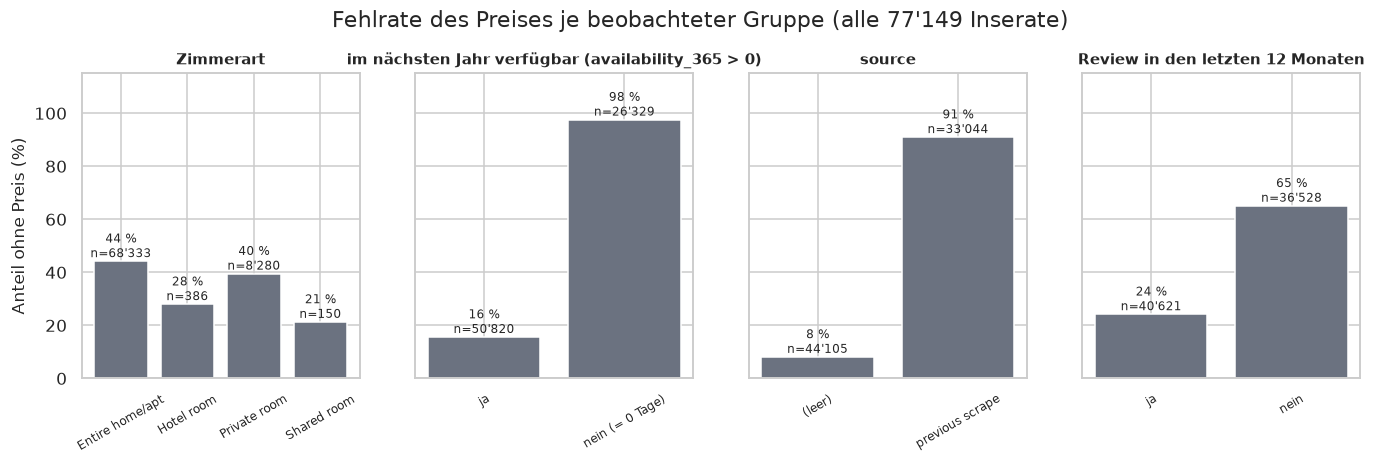

In [12]:
# Darstellen
fig, achsen = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (name, t) in zip(achsen, fehlraten.items()):
    ax.bar(t.index.astype(str), t["Fehlrate (%)"], color=G.GRAU)
    for i, (rate, n) in enumerate(zip(t["Fehlrate (%)"], t["Inserate"])):
        ax.text(i, rate + 1.5, f"{rate:.0f} %\nn={n:,}".replace(",", "'"), ha="center", fontsize=8)
    ax.set_title(name, fontsize=10)
    ax.tick_params(axis="x", rotation=30, labelsize=8)
achsen[0].set_ylabel("Anteil ohne Preis (%)")
achsen[0].set_ylim(0, 115)
fig.suptitle("Fehlrate des Preises je beobachteter Gruppe (alle 77'149 Inserate)", y=1.04)
G.speichere(fig, "01_fehlrate_preis")
plt.show()

**Beobachtung**

- Inserate mit **0 verfügbaren Tagen** im nächsten Jahr haben zu 97.6 % keinen Preis, verfügbare Inserate nur zu 15.6 %.
- Inserate aus einem **früheren Scrape** (`source = previous scrape`) haben zu 91.0 % keinen Preis, die übrigen zu 8.1 %. Laut Dictionary sollte `source` sonst «neighbourhood search» enthalten. Im Snapshot ist dieses Feld leer. Wir lesen «leer» als «über die Quartiersuche gefunden». Das ist eine **Annahme**.
- Ohne Review in den letzten 12 Monaten fehlt der Preis zu 65.1 %, mit Review zu 24.2 %.
- Zwischen Zimmerarten und Arrondissements unterscheiden sich die Fehlraten weniger stark, aber deutlich (siehe Tabelle).

**Interpretation**

- **MCAR ist unplausibel**, weil die Fehlrate stark von beobachteten Merkmalen abhängt (NB01 §3.2).
- **Ob MAR oder MNAR vorliegt, lässt sich aus diesen Daten nicht entscheiden** (NB01 §3.4). Dafür müssten wir die fehlenden Preise kennen.
- **Vermutung (Annahme, nicht bewiesen):** Ein Preis fehlt vor allem, weil das Inserat im Abfragezeitraum **nicht buchbar** ist. Das kann ein ruhendes oder blockiertes Inserat sein oder eines, das nur noch aus einem alten Scrape stammt. Für ein solches Inserat gibt es keinen «angebotenen Preis», der fehlen könnte.

**Entscheidung: keine Imputation des Preises**

- Eine Imputation, etwa mit dem Gruppenmedian, würde einen Angebotspreis für Inserate erfinden, die gar nicht angeboten werden.
- Hinge das Fehlen zusätzlich vom Preis selbst ab (MNAR), wäre jede Standardimputation verzerrt (VL01 S. 36).
- Wir **definieren die Zielpopulation** deshalb ausdrücklich als «im Abfragezeitraum buchbar angebotene Inserate». Im nächsten Abschnitt prüfen wir, wie sich diese Basis von allen Inseraten unterscheidet.

---
## 5. Selektionsfolgen: Inserate mit und ohne Preis im Vergleich

Der Ausschluss der Inserate ohne Preis ist eine Auswahl. Wenn sich die beiden Gruppen in Zimmerart, Grösse oder Lage unterscheiden, gelten unsere Aussagen nur für die ausgewählte Gruppe. Das ist das Survivorship-Argument aus VL01 S. 21.

In [13]:
hat_preis = alle["preis_eur"].notna().map({True: "mit Preis", False: "ohne Preis"})

vergleich = pd.concat(
    {
        "Anteil Ganze Unterkunft (%)": 100 * alle["room_type"].eq("Entire home/apt").groupby(hat_preis).mean(),
        "Anteil Privatzimmer (%)": 100 * alle["room_type"].eq("Private room").groupby(hat_preis).mean(),
        "Median Gäste (accommodates)": alle["accommodates"].groupby(hat_preis).median(),
        "Anteil ≥ 4 Gäste (%)": 100 * alle["accommodates"].ge(4).groupby(hat_preis).mean(),
        "Anteil Host mit ≥ 2 Inseraten (%)": 100 * alle["inserate_des_hosts"].ge(2).groupby(hat_preis).mean(),
        "Anteil mit Review in 12 Monaten (%)": 100 * alle["number_of_reviews_ltm"].gt(0).groupby(hat_preis).mean(),
        "Inserate": alle.groupby(hat_preis).size(),
    },
    axis=1,
).T.round(1)
D.speichere_tabelle(vergleich, "01_vergleich_mit_ohne_preis")
vergleich

preis_eur,mit Preis,ohne Preis
Anteil Ganze Unterkunft (%),87.60,89.90
Anteil Privatzimmer (%),11.50,9.70
Median Gäste (accommodates),3.00,2.00
Anteil ≥ 4 Gäste (%),45.20,36.70
Anteil Host mit ≥ 2 Inseraten (%),45.90,23.30
Anteil mit Review in 12 Monaten (%),70.80,29.20
Inserate,43'537.00,33'612.00


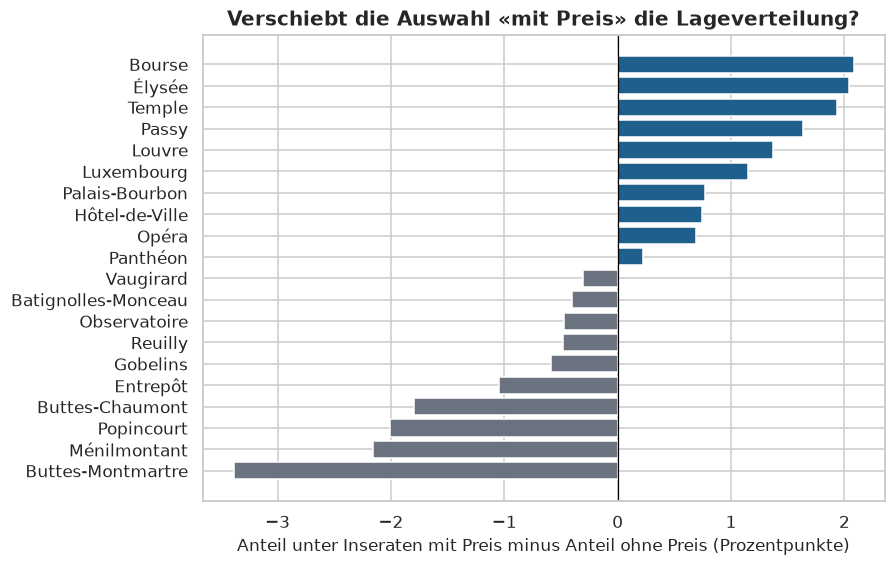

Grösste Verschiebung: 3.39 Prozentpunkte


In [14]:
# Lage: Anteil je Arrondissement mit und ohne Preis (Prozentpunkte-Differenz)
anteil_arr = pd.crosstab(alle["arrondissement"], hat_preis, normalize="columns") * 100
anteil_arr["Differenz (pp)"] = anteil_arr["mit Preis"] - anteil_arr["ohne Preis"]
anteil_arr = anteil_arr.sort_values("Differenz (pp)")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(anteil_arr.index, anteil_arr["Differenz (pp)"], color=np.where(anteil_arr["Differenz (pp)"] > 0, G.FARBEN_ZIMMERART["Entire home/apt"], G.GRAU))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Verschiebt die Auswahl «mit Preis» die Lageverteilung?",
       xlabel="Anteil unter Inseraten mit Preis minus Anteil ohne Preis (Prozentpunkte)")
G.speichere(fig, "01_selektion_lage")
plt.show()
print(f"Grösste Verschiebung: {anteil_arr['Differenz (pp)'].abs().max():.2f} Prozentpunkte")

**Beobachtung.** Inserate mit Preis unterscheiden sich deutlich von denen ohne Preis:

- **Host und Aktivität:** 45.9 % gehören Hosts mit ≥ 2 Inseraten (ohne Preis: 23.3 %). 70.8 % hatten ein Review in den letzten 12 Monaten (ohne Preis: 29.2 %).
- **Kapazität:** Inserate mit Preis sind grösser. Median 3 statt 2 Gäste, und 45.2 % statt 36.7 % bieten Platz für ≥ 4 Gäste.
- **Zimmerart:** ähnlich verteilt (87.6 % gegenüber 89.9 % ganze Unterkünfte).
- **Lage:** Der Anteil einzelner Arrondissements verschiebt sich um höchstens 3.4 Prozentpunkte.

**Interpretation.** Die Auswahl «mit Preis» bevorzugt **aktive, grössere und häufiger professionell betriebene** Inserate. Das passt zur Vermutung aus Abschnitt 4: Kleine Wohnungen von Privatpersonen, die nur gelegentlich vermietet werden, sind öfter gerade nicht buchbar.

**Folgen für die weitere Analyse**

- Ein Gesamtmedian «aller Paris-Airbnbs» wäre verzerrt. Wir berichten deshalb Kennzahlen **je Zimmerart und Kapazitätsstufe**, wo diese Verschiebung weniger ins Gewicht fällt.
- Die Lagevergleiche sind von der Selektion nur wenig berührt.

Über die **Preise** der Inserate ohne Preis wissen wir nichts. Eine Aussage wie «Paris-Airbnbs kosten im Median …» gilt deshalb nur für die angebotenen Inserate. Den Einfluss der Mehrfach-Hosts prüfen wir in Abschnitt 8 und in NB04.

---
## 6. Ungültige und unplausible Werte

Hier gehen wir die Prüffragen aus NB03_Ausreisserregeln §3 durch:

1. Kann der Wert überhaupt vorkommen?
2. Stimmen Einheit und Erfassung?

Ob hohe Preise plausibel sind, entscheidet erst NB02 mit Fallnotizen.

In [15]:
kontrollen = pd.Series(
    {
        "Preis ≤ 0": int((alle["preis_eur"] <= 0).sum()),
        "Preis fehlt trotz Preistext": int((alle["price"].notna() & alle["preis_eur"].isna()).sum()),
        "accommodates ≤ 0": int((alle["accommodates"] <= 0).sum()),
        "accommodates > 16": int((alle["accommodates"] > 16).sum()),
        "Abfrage 'nicht verfügbar', aber Preis vorhanden": int((alle["flag_abfrage_nicht_verfuegbar"] & alle["preis_eur"].notna()).sum()),
        "davon ohne Währungsangabe": int((alle["flag_abfrage_nicht_verfuegbar"] & alle["preis_eur"].notna() & alle["abfrage_waehrung"].isna()).sum()),
        "Abfragedauer ≤ 0 Nächte": int((alle["abfrage_naechte"] <= 0).sum()),
    },
    name="Anzahl",
)
kontrollen.to_frame()

,Anzahl
Preis ≤ 0,0
Preis fehlt trotz Preistext,0
accommodates ≤ 0,0
accommodates > 16,0
"Abfrage 'nicht verfügbar', aber Preis vorhanden",531
davon ohne Währungsangabe,531
Abfragedauer ≤ 0 Nächte,0


In [16]:
print("Preis pro Nacht der Inserate mit Preis (EUR):")
print(mit_preis["preis_eur"].describe(percentiles=[0.01, 0.5, 0.99, 0.999]).round(2).to_string())
print("\nDie fünf höchsten Preise (Details und Entscheidung in NB02):")
mit_preis.nlargest(5, "preis_eur")[["id", "preis_eur", "room_type", "accommodates", "bedrooms", "abfrage_naechte", "number_of_reviews"]]

Preis pro Nacht der Inserate mit Preis (EUR):
count    43'537.00
mean        337.20
std         867.50
min          10.38
1%           46.51
50%         218.00
99%       1'871.64
99.9%     8'377.91
max     100'666.10

Die fünf höchsten Preise (Details und Entscheidung in NB02):


,id,preis_eur,room_type,accommodates,bedrooms,abfrage_naechte,number_of_reviews
44189,1073735761485091887,100'666.10,Entire home/apt,7,4.00,21.00,8
52036,1140015032188028758,70'080.00,Entire home/apt,6,3.00,1.00,3
29872,608065383770041323,46'789.00,Entire home/apt,2,1.00,1.00,6
5821,7447891,34'536.67,Entire home/apt,2,1.00,3.00,2
43301,1025116958672853142,22'516.00,Entire home/apt,8,4.00,1.00,0


**Beobachtung**

- Es gibt **keine unmöglichen Werte**: keine Preise ≤ 0, keine Kapazität ≤ 0 und keine Parsingverluste.
- Der höchste Preis liegt bei rund 100 000 € pro Nacht, also gut 400-mal über dem Median der bepreisten Inserate (218 €).
- 531 Abfragen melden «nicht verfügbar», liefern aber trotzdem einen Preis, und zwar ohne Währungsangabe.

**Entscheidung**

- Kein Wert wird hier entfernt. Die 531 Abfragen kennzeichnen wir (`flag_abfrage_nicht_verfuegbar`) und schliessen sie in NB04 probeweise aus.
- Hohe Preise sind nicht unmöglich, nur zweifelhaft. Sie bekommen nach der vorab festgelegten Regel ein Kennzeichen `flag_extrem`: Preis ≥ 10 000 € oder mehr als 1 000 € pro Person und Nacht. Die Fallprüfung folgt in NB02.

---
## 7. Bereinigungstabelle und Analysedatensatz

Jeder Filter steht mit Regel, Begründung und Zeilenzahl in der Tabelle. Kennzeichnungen sind **keine** Filter: Die betroffenen Zeilen bleiben im Kern.

In [17]:
D.speichere_tabelle(bereinigung, "01_bereinigungstabelle", index=False)
bereinigung

,Schritt,Regel,Begründung,Zeilen vorher,entfernt,Anteil entfernt (%),Zeilen nachher
0,0 Rohdaten,keine,"vollständiger Snapshot, ein Inserat je Zeile",77149,0,0.00,77149
1,1 Preis beobachtet,preis_eur nicht fehlend,Kein Angebotspreis = kein buchbares Angebot im...,77149,33612,43.60,43537
2,2 Preis > 0,preis_eur > 0,Preis 0 oder negativ wäre ungültig,43537,0,0.00,43537
3,3 Kurzaufenthalt-Abfrage,abfrage_naechte < 28,Ab 28 Nächten liefert Airbnb einen rabattierte...,43537,5953,13.70,37584


In [18]:
flags = D.flag_tabelle(kern)
D.speichere_tabelle(flags, "01_kennzeichnungen_kern", index=False)
flags

,Kennzeichnung,Regel,Bedeutung,betroffen,Anteil am Kern (%)
0,flag_extrem,preis_eur ≥ 10'000 oder Preis pro Person > 1'000,inhaltlich zweifelhaft hoch; nicht als Fehler ...,117,0.31
1,flag_abfrage_nicht_verfuegbar,abfrage_verfuegbar == False,"Abfrage meldet 'nicht verfügbar', liefert aber...",531,1.41


In [19]:
# Selbstkontrolle der Nenner: Summe der entfernten Zeilen + Kern = Rohdaten
assert bereinigung["entfernt"].sum() + len(kern) == len(roh)
assert kern["preis_eur"].notna().all() and (kern["abfrage_naechte"] < D.GRENZE_MONATSABFRAGE).all()
print(f"Kern-Analysedatensatz: {len(kern):,} Inserate von {kern['host_id'].nunique():,} Hosts "
      f"({len(kern) / len(roh):.1%} der Rohdaten)".replace(",", "'"))
print(kern["zimmerart"].value_counts().to_string())

# Reproduzierbar abgeleiteter Analysedatensatz (die Rohdatei bleibt unverändert)
spalten = ["id", "host_id", "preis_eur", "zimmerart", "accommodates", "bedrooms", "arrondissement",
           "abfrage_naechte", "abfrage_checkin", "abfrage_vorlauf_tage", "inserate_des_hosts",
           "number_of_reviews", "flag_extrem", "flag_abfrage_nicht_verfuegbar"]
D.VERARBEITET.mkdir(parents=True, exist_ok=True)
kern[spalten].to_csv(D.VERARBEITET / "analysedatensatz_kern.csv.gz", index=False)
print("gespeichert:", (D.VERARBEITET / "analysedatensatz_kern.csv.gz").relative_to(PROJEKT))

Kern-Analysedatensatz: 37'584 Inserate von 25'382 Hosts (48.7% der Rohdaten)
zimmerart
Entire home/apt    32292
Private room        4908
Hotel room           266
Shared room          118


gespeichert: data/processed/analysedatensatz_kern.csv.gz


**Kleine Gruppen.** Hotelzimmer (266) und geteilte Zimmer (118) sind klein, und sie sind ein anderes Produkt. Wir beschreiben sie, stützen die Hauptaussagen aber auf «Ganze Unterkunft» und «Privatzimmer».

---
## 8. Abhängigkeit durch Mehrfach-Hosts

Inserate desselben Hosts sind keine unabhängigen Beobachtungen. Ein professioneller Betreiber setzt Preise oft nach einem einheitlichen Schema, und viele Inserate eines einzigen Hosts können das Bild einer Gruppe prägen.

In [20]:
je_host = kern.groupby("host_id").size()
print(f"Hosts im Kern: {len(je_host):,}; davon mit genau 1 Inserat: {(je_host == 1).mean():.1%}".replace(",", "'"))
print(f"Grösster Host: {je_host.max()} Inserate im Kern")

host_klasse = pd.cut(kern["inserate_des_hosts"], [0, 1, 2, 9, 10_000], labels=["1", "2", "3–9", "≥ 10"])
host_tabelle = pd.DataFrame(
    {
        "Inserate": kern.groupby(host_klasse, observed=True).size(),
        "Anteil am Kern (%)": (100 * kern.groupby(host_klasse, observed=True).size() / len(kern)).round(1),
        "Median Preis (EUR)": kern.groupby(host_klasse, observed=True)["preis_eur"].median(),
    }
)
host_tabelle.index.name = "Inserate des Hosts (Scrape)"
D.speichere_tabelle(host_tabelle, "01_host_struktur")
host_tabelle

Hosts im Kern: 25'382; davon mit genau 1 Inserat: 88.5%
Grösster Host: 227 Inserate im Kern


,Inserate,Anteil am Kern (%),Median Preis (EUR)
Inserate des Hosts (Scrape),,,
1,21620,57.50,215.00
2,3257,8.70,209.30
3–9,5323,14.20,269.00
≥ 10,7384,19.60,323.75


**Beobachtung**

- Rund 42 % der Kern-Inserate gehören Hosts mit mehr als einem Inserat. Knapp 20 % gehören Hosts mit mindestens zehn Inseraten.
- Der Medianpreis ist bei Hosts mit ≥ 10 Inseraten deutlich höher.

**Interpretation.** Das ist ein **möglicher Störfaktor**. Wenn professionelle Hosts in bestimmten Gruppen häufiger sind, könnten Gruppenunterschiede teilweise ihre Preissetzung widerspiegeln. Kausal deuten wir das nicht. NB04 prüft deshalb alle Hauptaussagen auch mit **einem zufällig gezogenen Inserat pro Host** (Seed 42).

---
## 9. Antwort auf Teilfrage 1

**Was misst der Preis?** Einen **angebotenen Preis pro Nacht in EUR**. Er stammt aus einer Preisabfrage für einen bestimmten Termin und eine bestimmte Dauer, die meist dem Mindestaufenthalt entspricht. Er ist weder ein bezahlter Preis noch Umsatz noch ein Mass für Nachfrage. Abfragen ab 28 Nächten liefern rabattierte Monatspreise und werden für die Hauptanalyse getrennt.

**Für welche Inserate liegt ein Preis vor?** Für 43 537 von 77 149 Inseraten (56.4 %). Der Preis fehlt vor allem bei Inseraten, die im nächsten Jahr keinen verfügbaren Tag haben (97.6 % ohne Preis) oder nur aus einem früheren Scrape stammen (91.0 % ohne Preis). Wir imputieren nicht, sondern beschränken die Aussagen auf **buchbar angebotene Inserate**.

**Wie unterscheiden sich Inserate mit und ohne Preis?** Inserate mit Preis sind aktiver, grösser und gehören häufiger Mehrfach-Hosts. Bei Zimmerart und Lage sind die Unterschiede klein. Der **Analysedatensatz** umfasst nach dem Ausschluss der Monatsabfragen 37 584 Inserate von 25 382 Hosts.

**Grenzen**

- Die Selektion durch die Suche von Inside Airbnb können wir nicht beziffern.
- Ob die fehlenden Preise MAR oder MNAR sind, lässt sich nicht prüfen.
- Termin und Dauer der Abfrage sind Messbedingungen, die wir in NB04 prüfen.

**Übergang zu NB02.** Bevor wir Gruppen vergleichen, beschreiben wir die Form der Preisverteilung. Daraus folgt, welche Kennzahlen tragen und wie stark die extremen Preise sie beeinflussen.